# Practical 6 – Clustering on a Real-World Dataset

**Name :- Pushkar Parakh Div:-E Batch:-E1 Roll NO:- 313 PRN :- 202401040313**

**GITHUB REPO** :- https://github.com/pushkarparakh/AIML-313/blob/main/CA/Practical%206/Real_World_Wine_Clustering.ipynb

## Aim
Apply clustering algorithms to a real-world dataset, identify useful groups and evaluate the quality of the clusters using numerical metrics and plots.

**Dataset:** Wine recognition dataset (178 wine samples, 13 chemical measurements). The cultivar label is kept separate and is not used to train the clustering models.

## 1. Import libraries and load the dataset

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import (
    silhouette_score, davies_bouldin_score,
    calinski_harabasz_score, adjusted_rand_score
)

DATA_PATH = Path("data") / "wine_clustering.csv"
if not DATA_PATH.exists():
    raise FileNotFoundError("Run this notebook from the Practical 6 folder so the data folder is available.")
df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
print("Missing values:", int(df.isna().sum().sum()))
display(df.head())
display(df.describe().T.round(2))

Dataset shape: (178, 14)
Missing values: 0


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,cultivar_reference
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


,count,mean,std,min,25%,50%,75%,max
alcohol,178.0,13.00,0.81,11.03,12.36,13.05,13.68,14.83
malic_acid,178.0,2.34,1.12,0.74,1.60,1.87,3.08,5.80
ash,178.0,2.37,0.27,1.36,2.21,2.36,2.56,3.23
alcalinity_of_ash,178.0,19.49,3.34,10.60,17.20,19.50,21.50,30.00
magnesium,178.0,99.74,14.28,70.00,88.00,98.00,107.00,162.00
total_phenols,178.0,2.30,0.63,0.98,1.74,2.36,2.80,3.88
flavanoids,178.0,2.03,1.00,0.34,1.20,2.13,2.88,5.08
nonflavanoid_phenols,178.0,0.36,0.12,0.13,0.27,0.34,0.44,0.66
proanthocyanins,178.0,1.59,0.57,0.41,1.25,1.56,1.95,3.58
color_intensity,178.0,5.06,2.32,1.28,3.22,4.69,6.20,13.00


## 2. Understand the data

Each row represents a wine sample. The 13 numeric columns record chemical properties such as alcohol, acidity, phenols, colour intensity and proline. The reference cultivar column is not supplied to the clustering algorithm.

In [2]:
feature_cols = [c for c in df.columns if c != "cultivar_reference"]
X = df[feature_cols].copy()
y_reference = df["cultivar_reference"].copy()  # kept only for later validation

print("Number of samples:", len(X))
print("Number of clustering features:", len(feature_cols))
print("Reference cultivar counts (not used for fitting):")
display(y_reference.value_counts().sort_index().rename("count").to_frame())

Number of samples: 178
Number of clustering features: 13
Reference cultivar counts (not used for fitting):


,count
cultivar_reference,
0,59
1,71
2,48


## 3. Preprocessing

In [3]:
# All clustering features are numeric and the dataset has no missing values.
# Standardization is important because the chemical measurements use different scales.
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

scaled_df = pd.DataFrame(X_scaled, columns=feature_cols)
display(scaled_df.describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
alcohol,178.0,-0.0,1.0,-2.43,-0.79,0.06,0.84,2.26
malic_acid,178.0,-0.0,1.0,-1.43,-0.66,-0.42,0.67,3.11
ash,178.0,-0.0,1.0,-3.68,-0.57,-0.02,0.70,3.16
alcalinity_of_ash,178.0,-0.0,1.0,-2.67,-0.69,0.00,0.60,3.15
magnesium,178.0,-0.0,1.0,-2.09,-0.82,-0.12,0.51,4.37
total_phenols,178.0,0.0,1.0,-2.11,-0.89,0.10,0.81,2.54
flavanoids,178.0,-0.0,1.0,-1.70,-0.83,0.11,0.85,3.06
nonflavanoid_phenols,178.0,0.0,1.0,-1.87,-0.74,-0.18,0.61,2.40
proanthocyanins,178.0,-0.0,1.0,-2.07,-0.60,-0.06,0.63,3.49
color_intensity,178.0,0.0,1.0,-1.63,-0.80,-0.16,0.49,3.44


## 4. Choose the number of clusters

The elbow method tracks within-cluster sum of squares (inertia). Silhouette score measures separation and cohesion (higher is better). Davies–Bouldin index measures similarity between clusters (lower is better).

In [4]:
k_values = range(2, 8)
inertias, silhouettes, db_scores = [], [], []

for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=20)
    labels = model.fit_predict(X_scaled)
    inertias.append(model.inertia_)
    silhouettes.append(silhouette_score(X_scaled, labels))
    db_scores.append(davies_bouldin_score(X_scaled, labels))

k_results = pd.DataFrame({
    "K": list(k_values),
    "Inertia (WCSS)": inertias,
    "Silhouette Score": silhouettes,
    "Davies-Bouldin Index": db_scores
})
display(k_results.round(3))

,K,Inertia (WCSS),Silhouette Score,Davies-Bouldin Index
0,2,1658.759,0.259,1.526
1,3,1277.928,0.285,1.389
2,4,1175.352,0.259,1.817
3,5,1107.007,0.232,1.681
4,6,1046.002,0.237,1.554
5,7,981.595,0.204,1.661


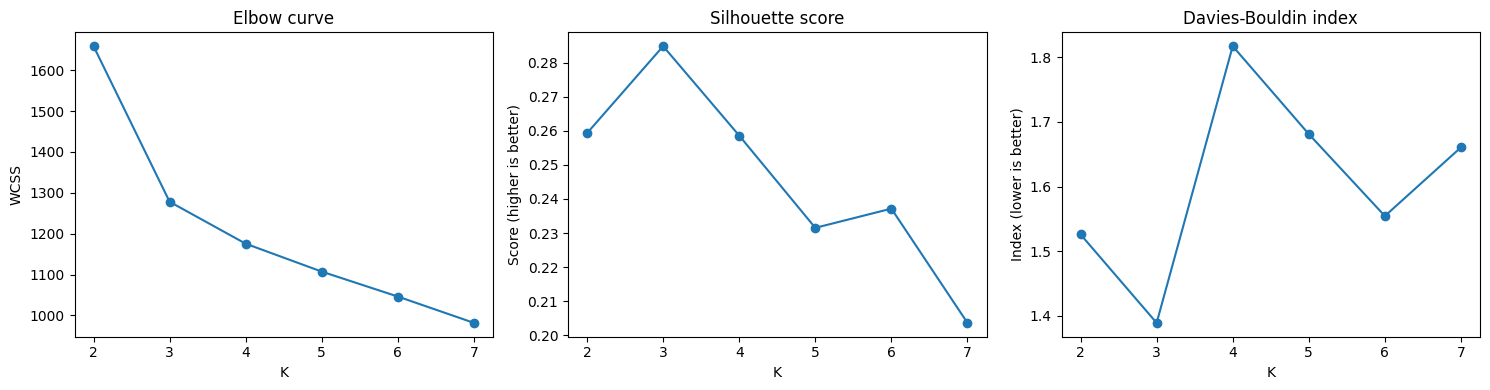

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].plot(k_results["K"], k_results["Inertia (WCSS)"], marker="o")
axes[0].set_title("Elbow curve")
axes[0].set_xlabel("K")
axes[0].set_ylabel("WCSS")

axes[1].plot(k_results["K"], k_results["Silhouette Score"], marker="o")
axes[1].set_title("Silhouette score")
axes[1].set_xlabel("K")
axes[1].set_ylabel("Score (higher is better)")

axes[2].plot(k_results["K"], k_results["Davies-Bouldin Index"], marker="o")
axes[2].set_title("Davies-Bouldin index")
axes[2].set_xlabel("K")
axes[2].set_ylabel("Index (lower is better)")

plt.tight_layout()
plt.show()

The three measures are considered together rather than choosing K from WCSS alone. In this run, K=3 has the highest silhouette score and the lowest Davies–Bouldin index among the tested values, so K=3 is selected for the final comparison.

## 5. Fit and compare clustering algorithms

In [6]:
best_k = 3

kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=20)
kmeans_labels = kmeans.fit_predict(X_scaled)

hierarchical = AgglomerativeClustering(n_clusters=best_k, linkage="ward")
hierarchical_labels = hierarchical.fit_predict(X_scaled)

def evaluate_clustering(X_values, labels):
    return {
        "Silhouette Score": silhouette_score(X_values, labels),
        "Davies-Bouldin Index": davies_bouldin_score(X_values, labels),
        "Calinski-Harabasz Score": calinski_harabasz_score(X_values, labels)
    }

comparison = pd.DataFrame({
    "K-Means": evaluate_clustering(X_scaled, kmeans_labels),
    "Agglomerative": evaluate_clustering(X_scaled, hierarchical_labels)
}).T
display(comparison.round(4))

,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Score
K-Means,0.2849,1.3892,70.9400
Agglomerative,0.2774,1.4186,67.6475


## 6. Visualize the clusters with PCA

Variance retained by two components: 55.41 %


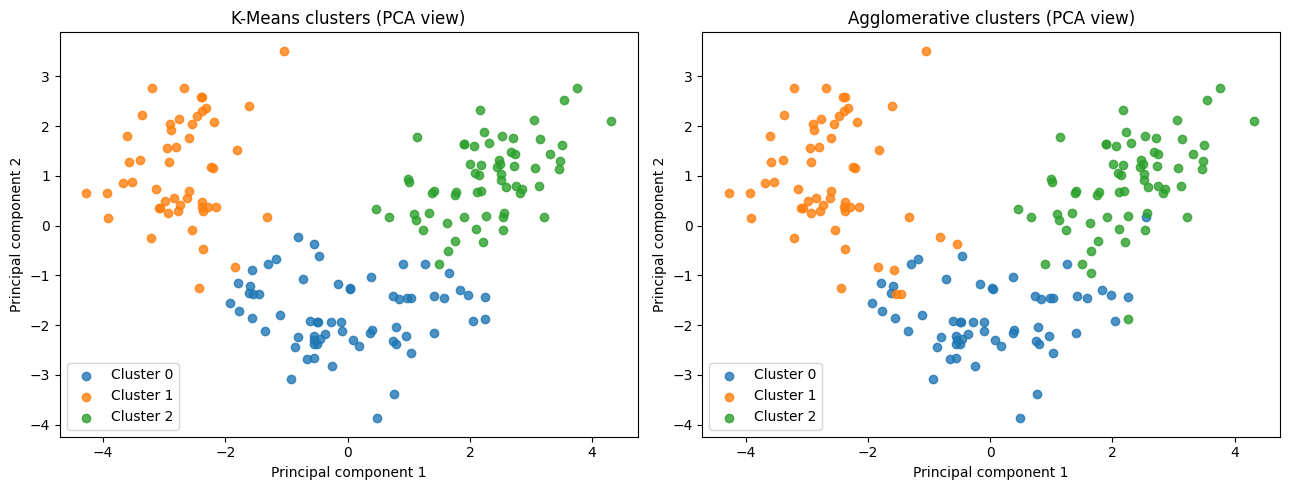

In [7]:
# PCA is used only to display the high-dimensional data in two dimensions.
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

print("Variance retained by two components:",
      round(pca.explained_variance_ratio_.sum() * 100, 2), "%")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for cluster_id in np.unique(kmeans_labels):
    mask = kmeans_labels == cluster_id
    axes[0].scatter(X_pca[mask, 0], X_pca[mask, 1],
                    label=f"Cluster {cluster_id}", alpha=0.8)
axes[0].set_title("K-Means clusters (PCA view)")
axes[0].set_xlabel("Principal component 1")
axes[0].set_ylabel("Principal component 2")
axes[0].legend()

for cluster_id in np.unique(hierarchical_labels):
    mask = hierarchical_labels == cluster_id
    axes[1].scatter(X_pca[mask, 0], X_pca[mask, 1],
                    label=f"Cluster {cluster_id}", alpha=0.8)
axes[1].set_title("Agglomerative clusters (PCA view)")
axes[1].set_xlabel("Principal component 1")
axes[1].set_ylabel("Principal component 2")
axes[1].legend()

plt.tight_layout()
plt.show()

## 7. Interpret the groups

In [8]:
clustered = X.copy()
clustered["cluster"] = kmeans_labels

cluster_sizes = clustered["cluster"].value_counts().sort_index().rename("sample_count")
cluster_profiles = clustered.groupby("cluster")[feature_cols].mean().round(2)
cluster_summary = cluster_sizes.to_frame().join(cluster_profiles)
display(cluster_summary)

,sample_count,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
cluster,,,,,,,,,,,,,,
0,65,12.25,1.90,2.23,20.06,92.74,2.25,2.05,0.36,1.62,2.97,1.06,2.80,510.17
1,51,13.13,3.31,2.42,21.24,98.67,1.68,0.82,0.45,1.15,7.23,0.69,1.70,619.06
2,62,13.68,2.00,2.47,17.46,107.97,2.85,3.00,0.29,1.92,5.45,1.07,3.16,1100.23


In [9]:
# Compare the discovered clusters with the known cultivar labels only after fitting.
# This is a validation check, not an input to K-means.
validation_table = pd.crosstab(
    pd.Series(kmeans_labels, name="K-Means cluster"),
    y_reference.rename("Reference cultivar")
)
display(validation_table)
print("Adjusted Rand Index against reference cultivar:",
      round(adjusted_rand_score(y_reference, kmeans_labels), 4))

Reference cultivar,0,1,2
K-Means cluster,,,
0,0,65,0
1,0,3,48
2,59,3,0


Adjusted Rand Index against reference cultivar: 0.8975


Cluster numbers are labels assigned by the algorithm; cluster 0 is not inherently better or worse than cluster 1. Use the cluster profile table to describe each group by its average chemical measurements. The cross-tabulation is a post-clustering check against the dataset's cultivar labels, which were excluded from training.

## 8. Conclusion

In [10]:
best_row = k_results.loc[k_results["K"] == best_k].iloc[0]
print(f"Selected K: {best_k}")
print(f"K-Means silhouette score: {best_row['Silhouette Score']:.4f}")
print(f"K-Means Davies-Bouldin index: {best_row['Davies-Bouldin Index']:.4f}")
print("\nAlgorithm comparison:")
display(comparison.round(4))

Selected K: 3
K-Means silhouette score: 0.2849
K-Means Davies-Bouldin index: 1.3892

Algorithm comparison:


,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Score
K-Means,0.2849,1.3892,70.9400
Agglomerative,0.2774,1.4186,67.6475


K-means and Agglomerative Clustering were applied to standardized chemical measurements from the Wine dataset. K=3 was selected after comparing the elbow curve, silhouette score and Davies–Bouldin index. PCA plots and cluster averages helped inspect and describe the resulting groups. The reference cultivar labels were used only after clustering for an additional validation check.

The scores indicate how well the groups are separated for this dataset; they do not prove that every sample belongs to a perfectly distinct natural group. Results can change with preprocessing, distance measures and model settings.

## Dataset source

Wine recognition dataset, originally donated by Forina et al. and distributed through the UCI Machine Learning Repository. The copy included here is provided by `scikit-learn`'s `load_wine` dataset loader.

- UCI dataset: https://archive.ics.uci.edu/dataset/109/wine
- scikit-learn documentation: https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_wine.html